In [5]:
import io
import math
import os
import random
import subprocess
import time
from functools import partial

# ==========================================
# Strict Reproducibility / Determinism Setup
# ==========================================
SEED_VALUE = 42

# 0. Force deterministic environment variables (Must be set before importing torch)
os.environ['PYTHONHASHSEED'] = str(SEED_VALUE)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import matplotlib.pyplot as plt
import numpy as np
import torch
import concurrent.futures

from torch import nn
from einops import rearrange
from einops.layers.torch import Rearrange

# 1. Python & NumPy seeds
random.seed(SEED_VALUE)
np.random.seed(SEED_VALUE)

# 2. PyTorch CPU & GPU seeds
torch.manual_seed(SEED_VALUE)
torch.cuda.manual_seed(SEED_VALUE)
torch.cuda.manual_seed_all(SEED_VALUE)

# 3. CuDNN Determinism Settings
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# 4. Enforce strict deterministic algorithms in PyTorch
torch.use_deterministic_algorithms(True, warn_only=True)

In [2]:

# 1. Clone the repository into a temporary folder
repo_url = "https://github.com/Graham-Brady-Research-Group/AutoregressiveEnsemble_SpatioTemporal_Evolution.git"
temp_dir = "temp_repo_files"

if os.path.exists(temp_dir):
    subprocess.run(["rm", "-rf", temp_dir])

print("Cloning repository...")
subprocess.run(["git", "clone", repo_url, temp_dir])

# 2. Move all .py files from the cloned repo to your current working directory
py_files_moved = 0
for root, dirs, files in os.walk(temp_dir):
    # Skip the .git folder itself
    if ".git" in root:
        continue
    for file in files:
        if file.endswith(".py"):
            src_path = os.path.join(root, file)
            dest_path = file  # Saves directly to your current working directory

            # If there are duplicate filenames in subfolders, you can prefix them or just copy
            subprocess.run(["cp", src_path, dest_path])
            print(f"Downloaded/Copied: {file}")
            py_files_moved += 1

# 3. Clean up the temporary directory
subprocess.run(["rm", "-rf", temp_dir])
print(f"\nSuccessfully brought {py_files_moved} Python file(s) into your working directory!")

Cloning repository...


Cloning into 'temp_repo_files'...


Downloaded/Copied: inference.py
Downloaded/Copied: unet_2d.py
Downloaded/Copied: viz_utils.py
Downloaded/Copied: main.py
Downloaded/Copied: dataprocessor_loadpathvar.py
Downloaded/Copied: utils.py
Downloaded/Copied: loadpath_gen.py

Successfully brought 7 Python file(s) into your working directory!


In [6]:
from unet_2d import Unet2D

In [7]:
def generate_pde_data(num_pdes=1000, time_steps=50, grid_points=128, device='cpu'):
    """
    Generates 1D Modified Shallow Water PDE trajectories efficiently 
    using fully vectorized PyTorch tensor operations.
    Returns: torch.Tensor of shape [num_pdes, time_steps, grid_points] (Height h)
    """
    # Fix: Use torch.arange instead of torch.linspace to mimic endpoint=False
    dx = (2 * np.pi) / grid_points
    x = torch.arange(0, grid_points, device=device) * dx

    t_max = 5.0
    dt_sim = 0.0001
    total_sim_steps = int(t_max / dt_sim) + 1
    save_every = max(1, total_sim_steps // time_steps)

    g = 9.81
    H = 1.0
    nu = 1e-4

    # 1. Initialize batch tensors [num_pdes, grid_points]
    h = H + torch.rand(num_pdes, grid_points, device=device) * 0.1 - 0.05
    u = torch.zeros(num_pdes, grid_points, device=device)

    # 2. Gaussian Forcing F(x) for each PDE trajectory:
    centers = torch.rand(num_pdes, 1, device=device) * (2 * np.pi)
    stds = torch.rand(num_pdes, 1, device=device) * 0.9 + 0.1       # Range: [0.1, 1.0]
    amplitudes = torch.rand(num_pdes, 1, device=device) * 0.8 + 0.1  # Max value < 1.0
    
    x_grid = x.unsqueeze(0)  # Shape: [1, grid_points]
    F = amplitudes * torch.exp(-((x_grid - centers) ** 2) / (2 * (stds ** 2))) # Shape: [num_pdes, grid_points]

    trajectory_h_list = []

    # Helper function for periodic shifts along the grid dimension
    def roll_tensor(tensor, shift):
        return torch.roll(tensor, shifts=shift, dims=1)

    # 3. Vectorized time integration loop
    for step in range(total_sim_steps):
        if step % save_every == 0 and len(trajectory_h_list) < time_steps:
            trajectory_h_list.append(h.clone())

        # First-order spatial derivatives (Central differences)
        du_dx = (roll_tensor(u, -1) - roll_tensor(u, 1)) / (2 * dx)
        dh_dx = (roll_tensor(h, -1) - roll_tensor(h, 1)) / (2 * dx)
        
        hu = h * u
        dhu_dx = (roll_tensor(hu, -1) - roll_tensor(hu, 1)) / (2 * dx)

        # Fourth-order hyperviscosity derivatives (\nabla^4)
        lap4_u = (roll_tensor(u, -2) - 4 * roll_tensor(u, -1) + 6 * u - 4 * roll_tensor(u, 1) + roll_tensor(u, 2)) / (dx ** 4)
        lap4_h = (roll_tensor(h, -2) - 4 * roll_tensor(h, -1) + 6 * h - 4 * roll_tensor(h, 1) + roll_tensor(h, 2)) / (dx ** 4)

        # Equations (16) & (17)
        du_dt = -u * du_dx - g * dh_dx - nu * lap4_u
        dh_dt = -H * du_dx - dhu_dx - nu * lap4_h + F

        # Forward Euler update
        u = u + dt_sim * du_dt
        h = h + dt_sim * dh_dt

    # Stack into [num_pdes, time_steps, grid_points]
    return torch.stack(trajectory_h_list[:time_steps], dim=1)

In [8]:
def prepare_training_pairs(pde_trajectories: torch.Tensor, history_steps: int = 10):
    X, Y = [], []
    num_samples, total_time, grid_size = pde_trajectories.shape

    for t in range(history_steps, total_time):
        x_seq = pde_trajectories[:, t - history_steps : t, :].permute(0, 2, 1)
        y_seq = pde_trajectories[:, t : t + 1, :].permute(0, 2, 1)
        X.append(x_seq)
        Y.append(y_seq)

    X = torch.cat(X, dim=0)
    Y = torch.cat(Y, dim=0)
    return X, Y

In [9]:
def plot_trajectory_summary(sample_idx, tag, mse, mae, r2, gt_arr, pred_arr, history_steps, grid_points):
    """Plots 2D spatiotemporal heatmaps, error map, and time-slice profile snapshots."""
    gt = gt_arr[sample_idx]
    pred = pred_arr[sample_idx]
    abs_err = np.abs(gt - pred)

    fig = plt.figure(figsize=(18, 9))
    fig.suptitle(
        f"{tag} — Sample #{sample_idx + 1}\n"
        f"MSE: {mse:.4e}  |  MAE: {mae:.4e}  |  R² Score: {r2:.4f}",
        fontsize=14, fontweight='bold', y=0.98
    )

    # 1. Ground Truth Heatmap
    ax1 = plt.subplot(2, 3, 1)
    im1 = ax1.imshow(gt, aspect='auto', cmap='viridis', origin='lower')
    ax1.set_title("Ground Truth Trajectory")
    ax1.set_xlabel("Grid Points (Space)")
    ax1.set_ylabel("Time Steps")
    ax1.axhline(y=history_steps - 0.5, color='white', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax1.legend(loc='upper right')
    plt.colorbar(im1, ax=ax1)

    # 2. Predicted Heatmap
    ax2 = plt.subplot(2, 3, 2)
    im2 = ax2.imshow(pred, aspect='auto', cmap='viridis', origin='lower')
    ax2.set_title("Predicted Trajectory (Ensemble)")
    ax2.set_xlabel("Grid Points (Space)")
    ax2.set_ylabel("Time Steps")
    ax2.axhline(y=history_steps - 0.5, color='white', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax2.legend(loc='upper right')
    plt.colorbar(im2, ax=ax2)

    # 3. Absolute Error Heatmap
    ax3 = plt.subplot(2, 3, 3)
    im3 = ax3.imshow(abs_err, aspect='auto', cmap='magma', origin='lower')
    ax3.set_title("Absolute Error Map |GT - Pred|")
    ax3.set_xlabel("Grid Points (Space)")
    ax3.set_ylabel("Time Steps")
    ax3.axhline(y=history_steps - 0.5, color='cyan', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax3.legend(loc='upper right')
    plt.colorbar(im3, ax=ax3)

    # 4. Spatial Snapshot Profiles across time steps
    t_total = gt.shape[0]
    snapshots = [
        int(history_steps * 0.5),                    # Mid-history
        history_steps + int((t_total - history_steps) * 0.3),  # Early rollout
        history_steps + int((t_total - history_steps) * 0.8)   # Late rollout
    ]

    for i, t_step in enumerate(snapshots):
        ax = plt.subplot(2, 3, 4 + i)
        ax.plot(gt[t_step], label='Ground Truth', color='black', linewidth=2)
        ax.plot(pred[t_step], label='Prediction', color='crimson', linestyle='--', linewidth=2)
        ax.set_title(f"Spatial Snapshot at Timestep t = {t_step}")
        ax.set_xlabel("Grid Points")
        ax.set_ylabel("Value")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [10]:



def conv_forward_pass_unet(model, x_batch, history_steps, ip_time_dim, device):
    """
    Adapter function to format 1D PDE inputs into a 2D spatial representation
    compatible with Unet2D downsampling blocks.
    """
    batch_size = x_batch.shape[0]
    channels = 3
    H, W = 8, 16  # 8 * 16 = 128 grid points

    # Extract latest time step across all spatial points: [Batch, 128]
    x_latest = x_batch[:, :, -1] if x_batch.ndim == 3 else x_batch

    # Reshape to [Batch, 1, 8, 16] and expand channels to [Batch, 3, 8, 16]
    x_spatial = x_latest.view(batch_size, 1, H, W)
    x_spatial = x_spatial.repeat(1, channels, 1, 1).to(device)

    # Temporal conditioning vector: [Batch, ip_time_dim]
    if x_batch.ndim == 3:
        t_cond = x_batch[:, 0, :ip_time_dim].to(device)
    else:
        t_cond = torch.zeros(batch_size, ip_time_dim, device=device)

    return model(x_spatial, t_cond)


def train_single_model(model_idx, train_loader, epochs, channels, ip_time_dim, history_steps, device, seed):
    """
    Utility function to instantiate and train a single Unet2D model instance 
    with a distinct random weight initialization seed.
    """
    # Set seed for reproducible weight initialization per model variant
    torch.manual_seed(seed)
    
    model = Unet2D(
        dim=16,
        out_dim=1,
        dim_mults=(1, 2, 4),
        channels=channels,
        ip_time_dim=ip_time_dim
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
    criterion = nn.MSELoss()

    model.train()
    print(f"\n--- Training Model {model_idx + 1}/4 (Seed: {seed}) ---")
    
    start_time = time.time()
    for epoch in range(1, epochs + 1):
        total_loss = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device).view(-1, 1, 8, 16)

            optimizer.zero_grad()
            preds = conv_forward_pass_unet(model, x_batch, history_steps, ip_time_dim, device)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        if epoch % 1 == 0 or epoch == 1:
            print(f"Model {model_idx + 1} | Epoch [{epoch}/{epochs}] - Loss: {avg_loss:.6f}")

    elapsed_time = time.time() - start_time
    print(f"Model {model_idx + 1} training complete in {elapsed_time:.2f}s")
    
    return model

Using device: cuda

Starting parallel training for 4 models (100 epochs each)...

--- Training Model 2/4 (Seed: 123) ---

--- Training Model 4/4 (Seed: 789) ---

--- Training Model 3/4 (Seed: 456) ---

--- Training Model 1/4 (Seed: 42) ---
Model 1 | Epoch [1/100] - Loss: 0.008016
Model 3 | Epoch [1/100] - Loss: 0.012361
Model 4 | Epoch [1/100] - Loss: 0.012446
Model 2 | Epoch [1/100] - Loss: 0.009336
Model 3 | Epoch [2/100] - Loss: 0.000423
Model 2 | Epoch [2/100] - Loss: 0.000453
Model 4 | Epoch [2/100] - Loss: 0.000491
Model 1 | Epoch [2/100] - Loss: 0.000475
Model 2 | Epoch [3/100] - Loss: 0.000424
Model 4 | Epoch [3/100] - Loss: 0.000405
Model 1 | Epoch [3/100] - Loss: 0.000412
Model 3 | Epoch [3/100] - Loss: 0.000413
Model 4 | Epoch [4/100] - Loss: 0.000409
Model 2 | Epoch [4/100] - Loss: 0.000381
Model 1 | Epoch [4/100] - Loss: 0.000379
Model 3 | Epoch [4/100] - Loss: 0.000396
Model 1 | Epoch [5/100] - Loss: 0.000383
Model 4 | Epoch [5/100] - Loss: 0.000391
Model 2 | Epoch [5/100

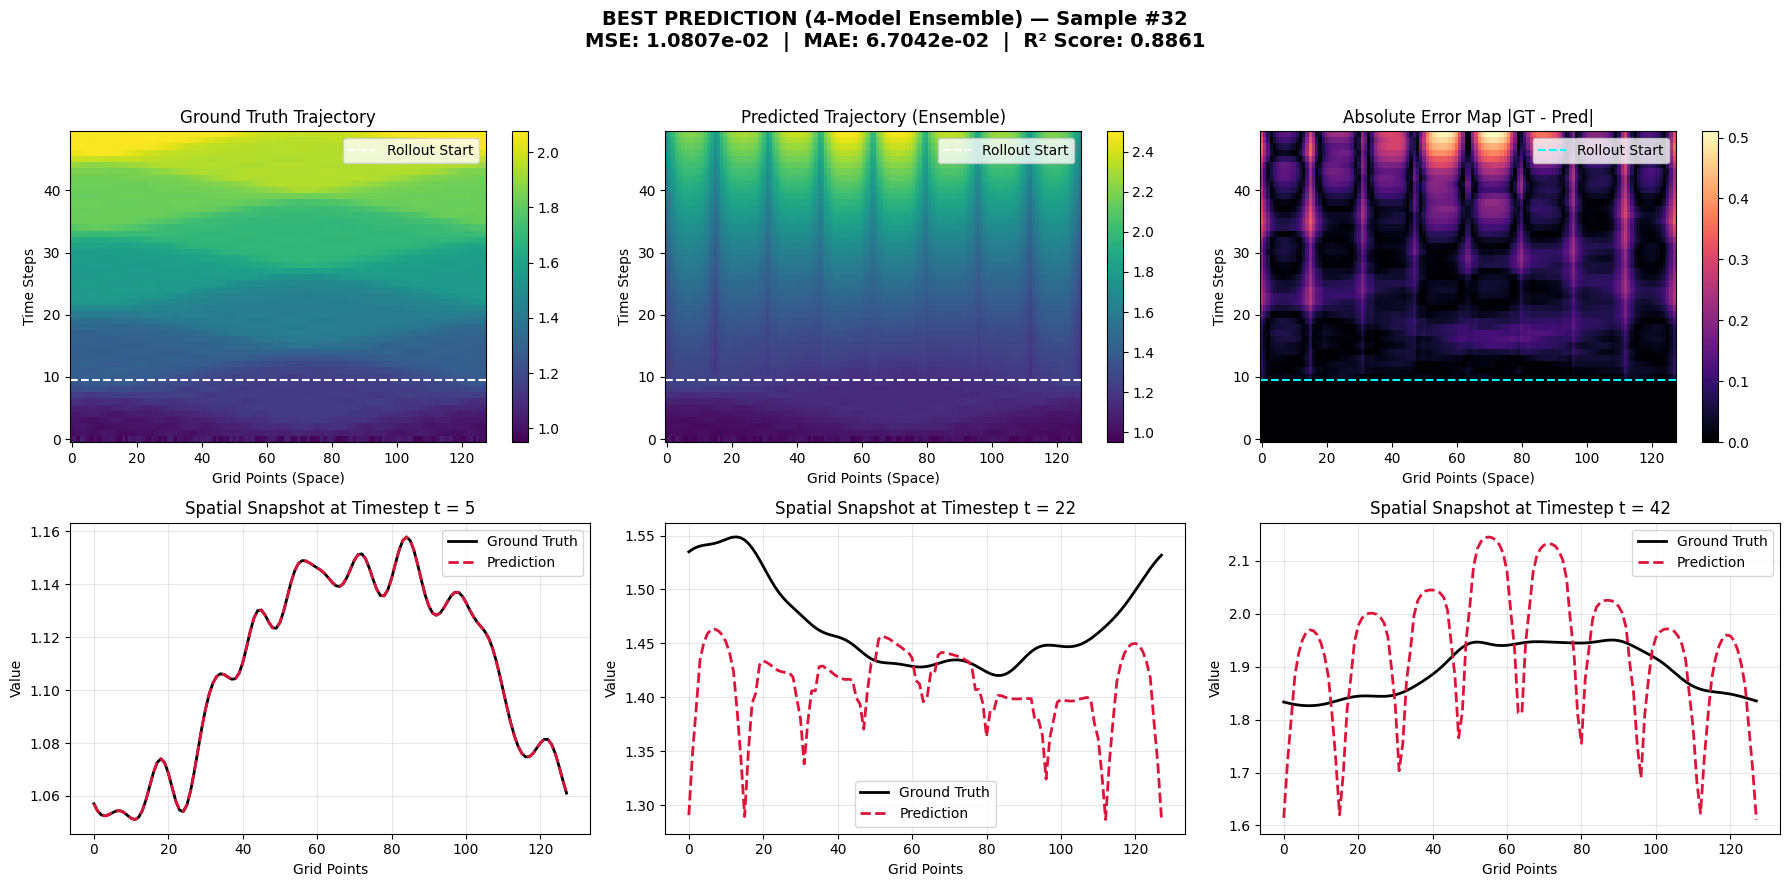

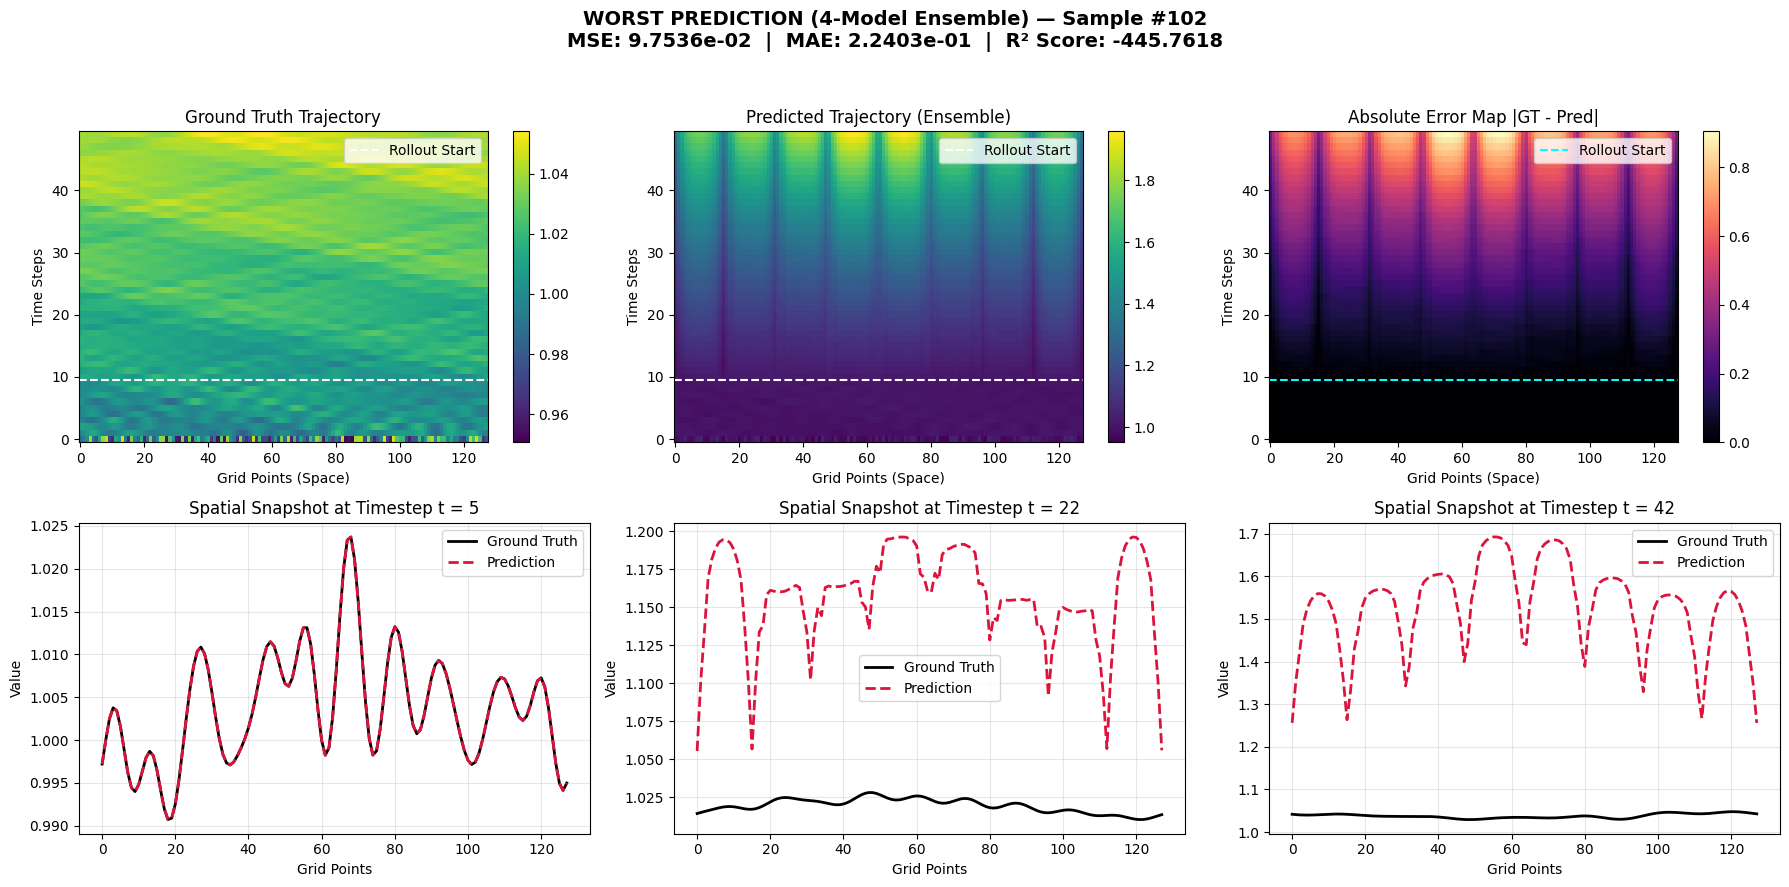

In [11]:
def _train_single_model_thread(args):
    """Worker function to train a single model in a separate thread with isolated RNG and dataloader."""
    (model_idx, X_train, Y_train, batch_size, epochs, channels, 
     ip_time_dim, history_steps, device, seed) = args
    
    # 1. Create a dedicated generator for this thread to ensure independent batch shuffling
    g = torch.Generator()
    g.manual_seed(seed)
    
    train_dataset = torch.utils.data.TensorDataset(X_train, Y_train)
    train_loader = torch.utils.data.DataLoader(
        train_dataset, 
        batch_size=batch_size, 
        shuffle=True, 
        generator=g, 
        num_workers=0
    )
    
    # 2. Set model-specific seed locally for weight initialization and training operations
    torch.manual_seed(seed)
    
    # Call your original training function directly
    model = train_single_model(
        model_idx=model_idx, train_loader=train_loader, epochs=epochs,
        channels=channels, ip_time_dim=ip_time_dim, history_steps=history_steps,
        device=device, seed=seed
    )
    
    return model_idx, model


def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}\n")

    num_pdes = 1000
    time_steps = 50
    grid_points = 128
    history_steps = 10
    ip_time_dim = 10
    channels = 3
    training_amount = int(0.8 * num_pdes)
    num_models = 4
    epochs = 100
    batch_size = 64

    # 1. Dataset Generation & Splitting
    all_pde_data = generate_pde_data(num_pdes, time_steps, grid_points)
    train_data = all_pde_data[:training_amount]
    test_data = all_pde_data[training_amount:]

    X_train, Y_train = prepare_training_pairs(train_data, history_steps=history_steps)
    
    # Move tensors to device once so workers can access them cleanly
    X_train_dev = X_train.to(device)
    Y_train_dev = Y_train.to(device).view(-1, 1, 8, 16)

    # Reset peak memory stats before starting parallel training
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)

    # 2. Train Model Ensemble in Parallel using Threads (Jupyter-friendly)
    seeds = [42, 123, 456, 789]
    
    print(f"Starting parallel training for {num_models} models ({epochs} epochs each)...")
    start_train_time = time.perf_counter()

    models = [None] * num_models
    with concurrent.futures.ThreadPoolExecutor(max_workers=num_models) as executor:
        futures = {
            executor.submit(
                _train_single_model_thread, 
                (i, X_train_dev, Y_train_dev, batch_size, epochs, channels, ip_time_dim, history_steps, device, seeds[i])
            ): i 
            for i in range(num_models)
        }
        for future in concurrent.futures.as_completed(futures):
            model_idx, trained_model = future.result()
            models[model_idx] = trained_model
            print(f"Model #{model_idx + 1} training completed.")

    total_train_time = time.perf_counter() - start_train_time
    train_mins, train_secs = divmod(total_train_time, 60)

    # --- Memory Consumption Print ---
    if device.type == 'cuda':
        max_mem_gb = torch.cuda.max_memory_allocated(device) / (1024 ** 3)
        current_mem_gb = torch.cuda.memory_allocated(device) / (1024 ** 3)
        print(f"\n[GPU Memory Stats after Parallel Training]")
        print(f"  - Peak Memory Allocated:   {max_mem_gb:.2f} GB")
        print(f"  - Current Memory Allocated: {current_mem_gb:.2f} GB")
    else:
        print("\n[Memory Stats] Running on CPU (CUDA memory tracking unavailable).")

    # 3. Autoregressive Rollout & Ensembling
    rollout_steps = time_steps - history_steps
    all_model_predictions = []

    print("\nRunning Autoregressive Rollouts...")
    for model in models:
        model.eval()
        current_history = test_data[:, :history_steps, :].permute(0, 2, 1).clone().to(device)
        model_frames = []

        with torch.no_grad():
            for step in range(rollout_steps):
                pred_next = conv_forward_pass_unet(model, current_history, history_steps, ip_time_dim, device)
                pred_1d = pred_next.view(-1, grid_points, 1)  # [batch, 128, 1]
                model_frames.append(pred_1d)

                # Update sliding history window autoregressively for this model
                current_history = torch.cat([current_history[:, :, 1:], pred_1d], dim=2)

        # Concatenate rollout steps along time dim: [batch, grid_points, rollout_steps] -> permute to [batch, rollout_steps, grid_points]
        model_rollout = torch.cat(model_frames, dim=2).permute(0, 2, 1).cpu()
        all_model_predictions.append(model_rollout)

    # 4. Average predictions across the 4 weight variants
    stacked_predictions = torch.stack(all_model_predictions, dim=0)
    ensemble_predictions_only = torch.mean(stacked_predictions, dim=0)  # [batch, rollout_steps, grid_points]

    # Prepend initial ground truth history steps to complete trajectory
    initial_frames = test_data[:, :history_steps, :]
    full_predicted_trajectories = torch.cat([initial_frames, ensemble_predictions_only], dim=1)

    # Print total ensemble training duration
    print(f"\nTotal Training Time for all {num_models} models (Parallel): {total_train_time:.2f} seconds ({int(train_mins)}m {train_secs:.2f}s)")

    # 5. Evaluate Trajectory Metrics on Ensembled Output
    ground_truth_np = test_data.numpy()
    predicted_np = full_predicted_trajectories.numpy()

    test_mse = np.mean((predicted_np[:, history_steps:, :] - ground_truth_np[:, history_steps:, :]) ** 2)
    print(f"4-Model Ensemble Rollout MSE on {int(0.2 * num_pdes)} Test Trajectories: {test_mse:.4e}")

    mse_per_sample = np.mean((ground_truth_np - predicted_np) ** 2, axis=(1, 2))
    mae_per_sample = np.mean(np.abs(ground_truth_np - predicted_np), axis=(1, 2))

    r2_per_sample = []
    for i in range(len(ground_truth_np)):
        y_true = ground_truth_np[i].flatten()
        y_pred = predicted_np[i].flatten()
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        r2_per_sample.append(r2)
    r2_per_sample = np.array(r2_per_sample)

    best_idx = int(np.argmin(mse_per_sample))
    worst_idx = int(np.argmax(mse_per_sample))

    print(f"Best Test Trajectory Index:  #{best_idx + 1} | MSE: {mse_per_sample[best_idx]:.4e}")
    print(f"Worst Test Trajectory Index: #{worst_idx + 1} | MSE: {mse_per_sample[worst_idx]:.4e}\n")

    # Plot Best & Worst Trajectories
    plot_trajectory_summary(
        best_idx, "BEST PREDICTION (4-Model Ensemble)", 
        mse_per_sample[best_idx], mae_per_sample[best_idx], r2_per_sample[best_idx],
        ground_truth_np, predicted_np, history_steps, grid_points
    )

    plot_trajectory_summary(
        worst_idx, "WORST PREDICTION (4-Model Ensemble)", 
        mse_per_sample[worst_idx], mae_per_sample[worst_idx], r2_per_sample[worst_idx],
        ground_truth_np, predicted_np, history_steps, grid_points
    )

if __name__ == "__main__":
    main()